# Unfallatlas 2025: Ensemble Models for Accident Severity

**Question (same as in `tiziano_baselines.ipynb`):** given that an accident with personal injury happened, how likely is it that
someone was **killed or seriously injured**? We predict a **probability between 0 and 1** by regressing on the binary
target `severe`. A regressor trained with squared error on a 0/1 target estimates exactly this probability, and its
loss is the **Brier score**.

The baselines showed that a linear model explains only a small part of the risk. Ensembles of trees can learn
interactions (motorcycle × rural road × night) that a linear model cannot. This notebook compares the three
ensemble families, all as **regressors** and with no neural networks:

| family | idea | models |
| --- | --- | --- |
| **Bagging** | many deep trees on bootstrap samples, averaged → lower variance | `BaggingRegressor`, `RandomForestRegressor`, `ExtraTreesRegressor` |
| **Boosting** | many shallow trees in sequence, each fixing the errors of the previous ones → lower bias | `AdaBoostRegressor`, `GradientBoostingRegressor`, `HistGradientBoostingRegressor` |
| **Stacking** | a meta-model learns how to combine different models | `VotingRegressor` (plain average), `StackingRegressor` |

All models are fitted on **train** (hyperparameters tuned by cross-validation or out-of-bag scores on train) and compared
on **validation**. The **test** split stays untouched. Splits come from `tiziano_splits.ipynb`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostRegressor,
    BaggingRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
    VotingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
MODEL_DIR = Path("models")

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                      "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ad"})
# same colours as tiziano_baselines.ipynb; one fixed colour per model in every plot
COLORS = {"Linear regression": "#2a78d6", "Random forest": "#1baf7a",
          "Hist gradient boosting": "#eb6834", "Stacking": "#6250d6"}
REFERENCE = "#8a8983"

## 1. Load the splits

Loader copied from `tiziano_splits.ipynb`. Two more stateless features are added row by row:

* `is_weekend`: Saturday or Sunday.
* `log_density`: log of inhabitants per km². Population density spans five orders of magnitude, and the log is a
  simple urban/rural indicator. Its 134 missing values (accidents in uninhabited areas) are imputed inside the pipeline.

In [2]:
TARGET = "severe"
OUTCOME_COLS = ["severity", "severe", "killed"]


def load_split(name):
    df = pd.read_csv(
        f"data/splits/{name}.csv.gz",
        dtype={"accident_id": str, "ags": str},
        parse_dates=["date"],
    )
    df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"]).astype(int)
    df["log_density"] = np.log1p(df["population_per_km2"])
    return df


train = load_split("train")
val = load_split("val")

y_train, y_val = train[TARGET], val[TARGET]
base_rate = y_train.mean()
print(f"train: {len(train):,} rows | val: {len(val):,} rows | base rate (train): {base_rate:.2%}")

train: 191,104 rows | val: 40,951 rows | base rate (train): 15.72%


## 2. Features and preprocessing

| group | columns | encoding |
| --- | --- | --- |
| road users | `bicycle`, `car`, `pedestrian`, `motorcycle`, `truck`, `other_vehicle`, `vulnerable`, `single_type`, `vulnerable_vs_vehicle`, `n_participant_types` | 0/1 and count, passed through |
| location | `state_name`, `longitude`, `latitude`, `log_density` | one-hot / numeric |
| location (fine) | `district` (512 districts) | **target encoding** |
| time | `hour_sin/cos`, `month_sin/cos`, `weekday`, `is_weekend` | numeric / one-hot |
| road conditions | `light`, `road_condition` | one-hot |

`accident_kind` and `accident_type` are **deliberately left out**: they describe *how* the accident happened
(collision with a pedestrian, leaving the road, …) and are only known after the fact, so the model uses only the road users,
the location, the time and the conditions.

**Target encoding** replaces each district with its share of severe accidents in the training data, shrunk towards the
base rate for small districts. `TargetEncoder` cross-fits this on the training data (each row is encoded with a value learned
from the *other* folds), so a district's own row does not leak its outcome into its feature. Municipalities (≈ 9,000)
are too sparse and are left out.

Trees do not need scaling, so the preprocessor only encodes and imputes. Every model below is a pipeline
`preprocessor → regressor`, so all encoding is learned from the training data only.

In [3]:
CATEGORICAL = ["state_name", "light", "road_condition", "weekday"]
BINARY = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle",
          "vulnerable", "single_type", "vulnerable_vs_vehicle", "is_weekend"]
NUMERIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types",
           "longitude", "latitude", "log_density"]
HIGH_CARDINALITY = ["district"]
FEATURES = CATEGORICAL + BINARY + NUMERIC + HIGH_CARDINALITY

X_train, X_val = train[FEATURES], val[FEATURES]


def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("bin", "passthrough", BINARY),
        ("num", SimpleImputer(strategy="median"), NUMERIC),
        ("te", TargetEncoder(target_type="continuous",
                             cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)), HIGH_CARDINALITY),
    ], verbose_feature_names_out=False)


def make_model(regressor):
    return make_pipeline(make_preprocessor(), regressor)


print(f"{len(FEATURES)} raw features → {make_preprocessor().fit(X_train, y_train).transform(X_train.head()).shape[1]} model columns")

23 raw features → 48 model columns


## 3. Evaluation

Same metrics as the baselines:

1. **Probability quality:** Brier score (= MSE on the 0/1 target, lower is better), Brier skill score
   (improvement over always predicting the base rate) and log loss.
2. **Ranking:** ROC-AUC and PR-AUC (average precision; random = base rate ≈ 0.157).
3. **Decisions:** precision, recall and F1 when flagging accidents above a threshold.

One change from the baselines: tree ensembles nearly memorise the training rows, so a threshold chosen on *training*
predictions would be far too high. Here the F1-optimal threshold is chosen on **validation**. This makes the F1 slightly
optimistic, but equally so for every model; for the final model the validation threshold is then applied unchanged to test.

Regressors can predict slightly outside [0, 1]; predictions are clipped before scoring.

In [4]:
def predict_proba(model, X):
    return np.clip(model.predict(X), 0, 1)


def best_f1_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]


brier_constant = brier_score_loss(y_val, np.full(len(y_val), base_rate))
pred_val, rows = {}, []


def evaluate(name, model, family):
    p = predict_proba(model, X_val)
    pred_val[name] = p
    threshold = best_f1_threshold(y_val, p)
    flags = p >= threshold
    row = pd.Series({
        "family": family,
        "Brier": brier_score_loss(y_val, p),
        "Brier skill": 1 - brier_score_loss(y_val, p) / brier_constant,
        "log loss": log_loss(y_val, np.clip(p, 1e-6, 1 - 1e-6)),
        "ROC-AUC": roc_auc_score(y_val, p),
        "PR-AUC": average_precision_score(y_val, p),
        "threshold": threshold,
        "% flagged": flags.mean() * 100,
        "precision": precision_score(y_val, flags),
        "recall": recall_score(y_val, flags),
        "F1": f1_score(y_val, flags),
    }, name=name)
    rows[:] = [r for r in rows if r.name != name] + [row]
    return row.to_frame().T


def results_table():
    return pd.DataFrame(rows).round(4)

## 4. Reference: linear regression

The linear regression from the baselines, refitted on the new features (including the district target encoding and
population density). This is the score every ensemble has to beat.

In [5]:
linreg = make_model(LinearRegression()).fit(X_train, y_train)
evaluate("Linear regression", linreg, "reference")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Linear regression,reference,0.126404,0.045742,0.412756,0.663434,0.262798,0.179513,34.790359,0.245174,0.542728,0.337765


## 5. Bagging

Bagging (**b**ootstrap **agg**regat**ing**) trains many trees on random bootstrap samples of the training rows and
averages their predictions. A single tree has high variance (small data changes give a very different tree); averaging
many decorrelated trees cancels most of that variance while keeping the low bias.

### 5.1 One tree vs. bagged trees

`min_samples_leaf=50` keeps every leaf large enough to estimate a probability (a leaf with 3 accidents can only say 0, ⅓, ⅔ or 1).

In [6]:
tree = make_model(DecisionTreeRegressor(min_samples_leaf=50, random_state=RANDOM_STATE)).fit(X_train, y_train)
bagging = make_model(BaggingRegressor(
    DecisionTreeRegressor(min_samples_leaf=50),
    n_estimators=100, max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)

pd.concat([evaluate("Single tree", tree, "single tree"), evaluate("Bagging (trees)", bagging, "bagging")])

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Single tree,single tree,0.134099,-0.012352,0.504427,0.61069,0.228243,0.170213,39.005152,0.212671,0.527812,0.303182
Bagging (trees),bagging,0.126084,0.048159,0.411755,0.665011,0.268805,0.167537,39.017362,0.238453,0.591983,0.339966


### 5.2 Random forest

A random forest is bagging plus **feature subsampling**: each split only looks at a random subset of columns
(`max_features`). This decorrelates the trees further, because a dominant feature such as population density cannot sit
at the top of every tree.

**Tuning with out-of-bag (OOB) scores.** Each tree never sees about a third of the training rows (those not drawn in its
bootstrap sample). Predicting each row only with the trees that did not see it gives a free validation score on train,
without cross-validation. For a regressor the OOB score is R², and on a 0/1 target R² is the Brier skill score
against the training base rate.

In [7]:
oob_rows = []
for leaf in [20, 50, 100, 200]:
    for max_features in [0.2, 0.3, 0.5]:
        rf = make_model(RandomForestRegressor(
            n_estimators=150, min_samples_leaf=leaf, max_features=max_features,
            oob_score=True, n_jobs=-1, random_state=RANDOM_STATE,
        )).fit(X_train, y_train)
        oob_rows.append({"min_samples_leaf": leaf, "max_features": max_features,
                         "OOB Brier skill": rf[-1].oob_score_})

oob = pd.DataFrame(oob_rows)
best_rf = oob.loc[oob["OOB Brier skill"].idxmax()]
print(f"best: min_samples_leaf={best_rf['min_samples_leaf']:.0f}, max_features={best_rf['max_features']}")
oob.pivot(index="min_samples_leaf", columns="max_features", values="OOB Brier skill").round(4)

best: min_samples_leaf=100, max_features=0.3


max_features,0.2,0.3,0.5
min_samples_leaf,,,
20,0.0459,0.0447,0.0424
50,0.0473,0.0470,0.0463
100,0.0471,0.0475,0.0472
200,0.0465,0.0469,0.0470


In [8]:
random_forest = make_model(RandomForestRegressor(
    n_estimators=400, min_samples_leaf=int(best_rf["min_samples_leaf"]),
    max_features=best_rf["max_features"], n_jobs=-1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("Random forest", random_forest, "bagging")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Random forest,bagging,0.125837,0.050023,0.410781,0.668372,0.271669,0.168849,38.558277,0.240595,0.590273,0.341852


### 5.3 Extra trees

Extremely randomised trees go one step further: split thresholds are drawn at random instead of optimised. This adds
bias but removes even more variance, and each tree is cheaper to grow. They use the full training set (no bootstrap)
by default.

In [9]:
extra_trees = make_model(ExtraTreesRegressor(
    n_estimators=400, min_samples_leaf=int(best_rf["min_samples_leaf"]), max_features=0.5,
    n_jobs=-1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("Extra trees", extra_trees, "bagging")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Extra trees,bagging,0.125926,0.049349,0.411039,0.667847,0.270167,0.174005,35.427706,0.246829,0.556401,0.34196


## 6. Boosting

Boosting grows **shallow trees one after another**. Each new tree focuses on what the ensemble so far gets wrong, so
boosting mainly reduces bias. The learning rate shrinks each tree's contribution; smaller rates need more trees but
generalise better.

### 6.1 AdaBoost

`AdaBoostRegressor` (AdaBoost.R2) reweights the training rows: rows with large errors get a higher weight and are
more likely to be sampled for the next tree. The final prediction is a weighted **median** of the trees, not a mean.

In [10]:
adaboost = make_model(AdaBoostRegressor(
    DecisionTreeRegressor(max_depth=3), n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("AdaBoost", adaboost, "boosting")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
AdaBoost,boosting,0.13008,0.017989,0.427048,0.647334,0.249971,0.212798,43.674147,0.222309,0.617775,0.32696


AdaBoost is the weakest ensemble here, and it is not a tuning problem. On a 0/1 target almost every row has an absolute
error close to either its probability or one minus it, so AdaBoost.R2 keeps upweighting the severe accidents, which are
mostly unpredictable noise. The weighted median also produces only a few distinct values, which hurts the ranking metrics.
**Gradient boosting** fits the residuals of the squared error directly and does not have this problem.

### 6.2 Gradient boosting

`GradientBoostingRegressor` fits each new tree to the residuals (`y − current prediction`) of the squared error.
`subsample=0.5` (stochastic gradient boosting) adds a bit of bagging: every tree sees a random half of the rows.

In [11]:
gradient_boosting = make_model(GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.5, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("Gradient boosting", gradient_boosting, "boosting")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Gradient boosting,boosting,0.125912,0.049457,0.411006,0.668831,0.26884,0.172257,35.361774,0.246599,0.554848,0.341445


### 6.3 Histogram gradient boosting (tuned)

`HistGradientBoostingRegressor` is the same algorithm, but it bins every feature into at most 255 values first.
It is an order of magnitude faster on 190k rows (similar to LightGBM), which makes cross-validated tuning affordable.
**Early stopping** on an internal 10 % slice of the training data picks the number of trees.

Hyperparameters are tuned with a randomised search, 3-fold CV on train, scored by MSE (= Brier score).

In [12]:
search = RandomizedSearchCV(
    make_model(HistGradientBoostingRegressor(max_iter=2000, early_stopping=True,
                                             n_iter_no_change=30, random_state=RANDOM_STATE)),
    param_distributions={
        "histgradientboostingregressor__learning_rate": loguniform(0.02, 0.2),
        "histgradientboostingregressor__max_leaf_nodes": randint(8, 64),
        "histgradientboostingregressor__min_samples_leaf": randint(20, 400),
        "histgradientboostingregressor__l2_regularization": loguniform(1e-3, 10),
        "histgradientboostingregressor__max_features": [0.5, 0.75, 1.0],
    },
    n_iter=20, cv=3, scoring="neg_mean_squared_error", n_jobs=-1, random_state=RANDOM_STATE,
).fit(X_train, y_train)

hist_gb = search.best_estimator_
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
print(f"best CV Brier: {-search.best_score_:.4f} | trees after early stopping: {hist_gb[-1].n_iter_}")
pd.Series({k.split("__")[1]: v for k, v in search.best_params_.items()}).to_frame("best value")

best CV Brier: 0.1261 | trees after early stopping: 198


,best value
l2_regularization,0.050191
learning_rate,0.032283
max_features,0.750000
max_leaf_nodes,36.000000
min_samples_leaf,210.000000


In [13]:
evaluate("Hist gradient boosting", hist_gb, "boosting")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Hist gradient boosting,boosting,0.125727,0.050849,0.410465,0.669682,0.271958,0.169134,37.012527,0.244837,0.5766,0.343723


**Learning curve.** The training loss keeps falling with every tree, while the held-out loss flattens; early stopping
cuts where the held-out loss stops improving.

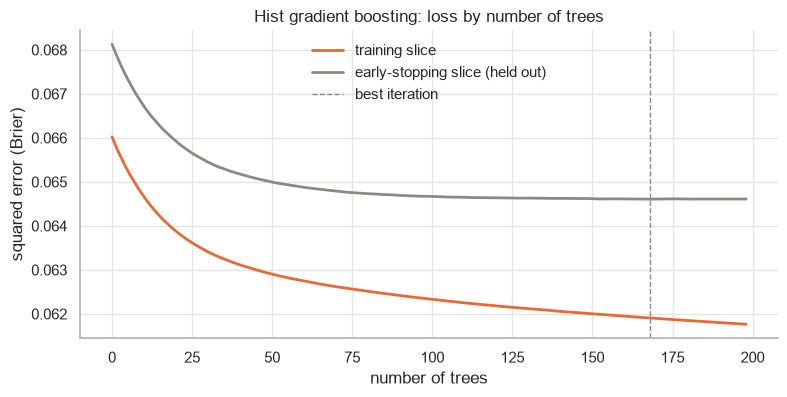

In [14]:
gb = hist_gb[-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(-gb.train_score_, lw=2, color=COLORS["Hist gradient boosting"], label="training slice")
ax.plot(-gb.validation_score_, lw=2, color=REFERENCE, label="early-stopping slice (held out)")
ax.axvline(gb.n_iter_ - gb.n_iter_no_change, color=REFERENCE, ls="--", lw=1, label="best iteration")
ax.set(xlabel="number of trees", ylabel="squared error (Brier)",
       title="Hist gradient boosting: loss by number of trees")
ax.legend(frameon=False)
plt.show()

## 7. Stacking

The models above make partly different mistakes: linear regression extrapolates smoothly, forests average local
neighbourhoods, boosting builds sharp interactions. Combining them can beat each one.

* **Voting** averages the predictions with equal weights. There is nothing to fit.
* **Stacking** trains a meta-model on the base models' **out-of-fold** predictions (5-fold CV on train), so the
  meta-model learns how far to trust each model on rows that model has not seen. The meta-model is a linear regression with
  non-negative weights: the result is an interpretable weighted average, and a model that adds nothing gets weight 0.

Base models: linear regression, random forest, extra trees and the tuned hist gradient boosting (AdaBoost and the slow
`GradientBoostingRegressor` are left out; they add nothing over hist gradient boosting).

In [15]:
base_models = [
    ("linear", linreg),
    ("random_forest", random_forest),
    ("extra_trees", extra_trees),
    ("hist_gb", hist_gb),
]

voting = VotingRegressor(base_models, n_jobs=1).fit(X_train, y_train)
evaluate("Voting (average)", voting, "stacking")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Voting (average),stacking,0.125713,0.050956,0.410292,0.670421,0.273355,0.168784,38.372689,0.242714,0.592604,0.344379


In [16]:
stacking = StackingRegressor(
    base_models,
    final_estimator=LinearRegression(positive=True),
    cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1,  # the forests already use all cores
).fit(X_train, y_train)

meta = stacking.final_estimator_
weights = pd.Series(meta.coef_, index=[name for name, _ in base_models], name="weight")
print(f"meta-model intercept: {meta.intercept_:.4f}, sum of weights: {weights.sum():.3f}")
display(weights.round(3).to_frame())
evaluate("Stacking", stacking, "stacking")

meta-model intercept: -0.0080, sum of weights: 1.050


,weight
linear,0.077
random_forest,0.139
extra_trees,0.224
hist_gb,0.610


,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Stacking,stacking,0.125642,0.051495,0.410107,0.670552,0.27324,0.168375,38.062563,0.2436,0.589963,0.344821


## 8. Comparison on validation

In [17]:
results = results_table()
results.sort_values("Brier")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Stacking,stacking,0.1256,0.0515,0.4101,0.6706,0.2732,0.1684,38.0626,0.2436,0.5900,0.3448
Hist gradient boosting,boosting,0.1257,0.0508,0.4105,0.6697,0.2720,0.1691,37.0125,0.2448,0.5766,0.3437
Voting (average),stacking,0.1257,0.0510,0.4103,0.6704,0.2734,0.1688,38.3727,0.2427,0.5926,0.3444
Random forest,bagging,0.1258,0.0500,0.4108,0.6684,0.2717,0.1688,38.5583,0.2406,0.5903,0.3419
Extra trees,bagging,0.1259,0.0493,0.4110,0.6678,0.2702,0.1740,35.4277,0.2468,0.5564,0.3420
Gradient boosting,boosting,0.1259,0.0495,0.4110,0.6688,0.2688,0.1723,35.3618,0.2466,0.5548,0.3414
Bagging (trees),bagging,0.1261,0.0482,0.4118,0.6650,0.2688,0.1675,39.0174,0.2385,0.5920,0.3400
Linear regression,reference,0.1264,0.0457,0.4128,0.6634,0.2628,0.1795,34.7904,0.2452,0.5427,0.3378
AdaBoost,boosting,0.1301,0.0180,0.4270,0.6473,0.2500,0.2128,43.6741,0.2223,0.6178,0.3270
Single tree,single tree,0.1341,-0.0124,0.5044,0.6107,0.2282,0.1702,39.0052,0.2127,0.5278,0.3032


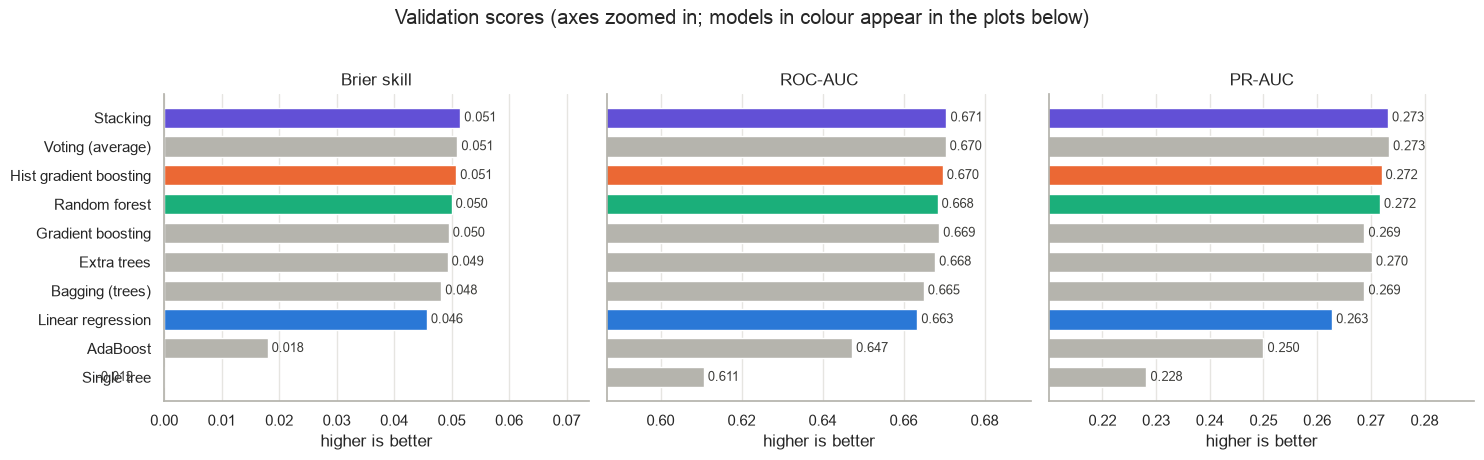

In [18]:
metrics = ["Brier skill", "ROC-AUC", "PR-AUC"]
order = results.sort_values("Brier skill").index
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, metric in zip(axes, metrics):
    values = results.loc[order, metric].astype(float)
    colors = [COLORS.get(name, "#b5b4ad") for name in order]
    ax.barh(order, values, color=colors, height=0.7)
    for i, v in enumerate(values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9, color="#3d3d3a")
    lo = values.min()
    ax.set_xlim(max(lo - (values.max() - lo) * 0.4, 0), values.max() + (values.max() - lo) * 0.35)
    ax.set(title=metric, xlabel="higher is better")
    ax.grid(axis="y", visible=False)
plt.suptitle("Validation scores (axes zoomed in; models in colour appear in the plots below)", y=1.02)
plt.tight_layout()
plt.show()

### Calibration and precision–recall

Four models in the plots: the linear reference, the best bagging model, the best boosting model and the stack.

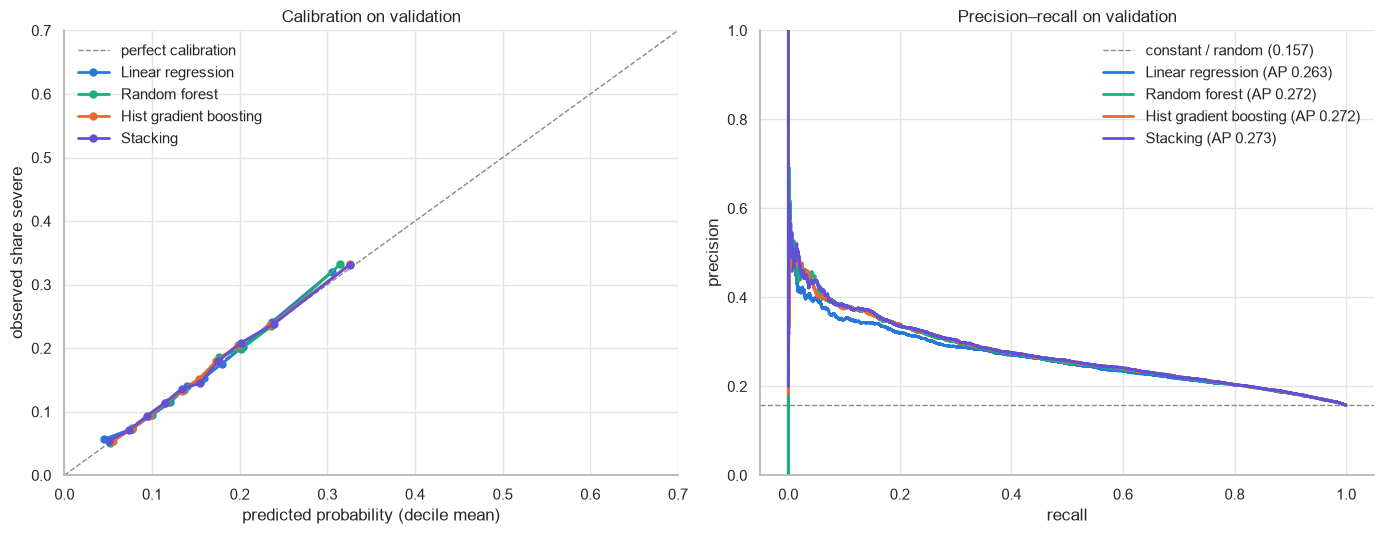

In [19]:
SHOWN = list(COLORS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
ax.plot([0, 0.7], [0, 0.7], color=REFERENCE, ls="--", lw=1, label="perfect calibration")
for name in SHOWN:
    frac_pos, mean_pred = calibration_curve(y_val, pred_val[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=5, lw=2, color=COLORS[name], label=name)
ax.set(xlabel="predicted probability (decile mean)", ylabel="observed share severe",
       title="Calibration on validation", xlim=(0, 0.7), ylim=(0, 0.7))
ax.legend(frameon=False)

ax = axes[1]
ax.axhline(y_val.mean(), color=REFERENCE, ls="--", lw=1, label=f"constant / random ({y_val.mean():.3f})")
for name in SHOWN:
    precision, recall, _ = precision_recall_curve(y_val, pred_val[name])
    ax.plot(recall, precision, lw=2, color=COLORS[name],
            label=f"{name} (AP {average_precision_score(y_val, pred_val[name]):.3f})")
ax.set(xlabel="recall", ylabel="precision", title="Precision–recall on validation", ylim=(0, 1))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Lift by risk decile

Validation accidents sorted by predicted risk and cut into ten equal groups; bars show the observed share of severe accidents per group.

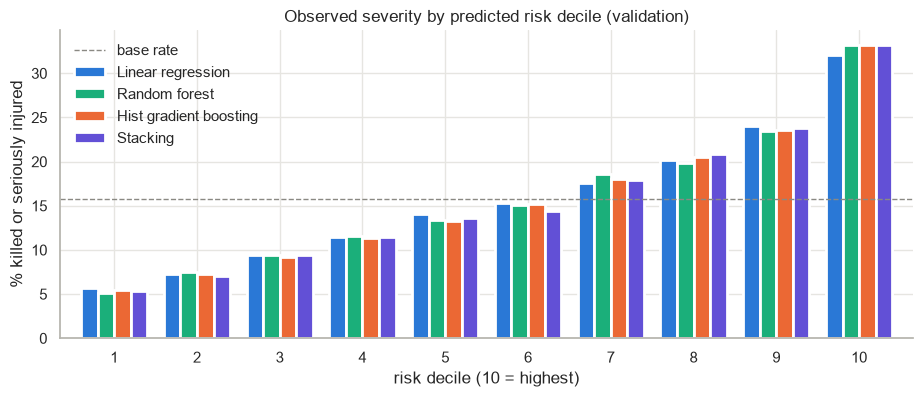

risk decile (10 = highest),1,2,3,4,5,6,7,8,9,10
Linear regression,5.6,7.3,9.5,11.5,14.0,15.3,17.5,20.2,24.1,32.0
Random forest,5.1,7.4,9.5,11.6,13.4,15.1,18.6,19.9,23.4,33.2
Hist gradient boosting,5.5,7.3,9.3,11.4,13.3,15.2,18.0,20.5,23.6,33.2
Stacking,5.4,7.1,9.4,11.4,13.7,14.5,18.0,20.9,23.8,33.2


In [20]:
lift = pd.DataFrame({
    name: pd.Series(y_val.to_numpy()).groupby(pd.qcut(pd.Series(pred_val[name]).rank(method="first"),
                                                      10, labels=range(1, 11))).mean()
    for name in SHOWN
}) * 100
lift.index.name = "risk decile (10 = highest)"

fig, ax = plt.subplots(figsize=(11, 4))
lift.plot.bar(ax=ax, color=[COLORS[c] for c in lift.columns], width=0.8, edgecolor="white", linewidth=2)
ax.axhline(y_val.mean() * 100, color=REFERENCE, ls="--", lw=1, label="base rate")
ax.set(ylabel="% killed or seriously injured", title="Observed severity by predicted risk decile (validation)")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False)
plt.show()
lift.round(1).T

## 9. What drives the predictions

**Permutation importance** of the best single model: shuffle one raw feature on validation and measure how much
the Brier score gets worse. Unlike impurity importance it is measured on unseen data, and it is computed per raw column,
so a one-hot encoded column such as `light` counts as one feature.

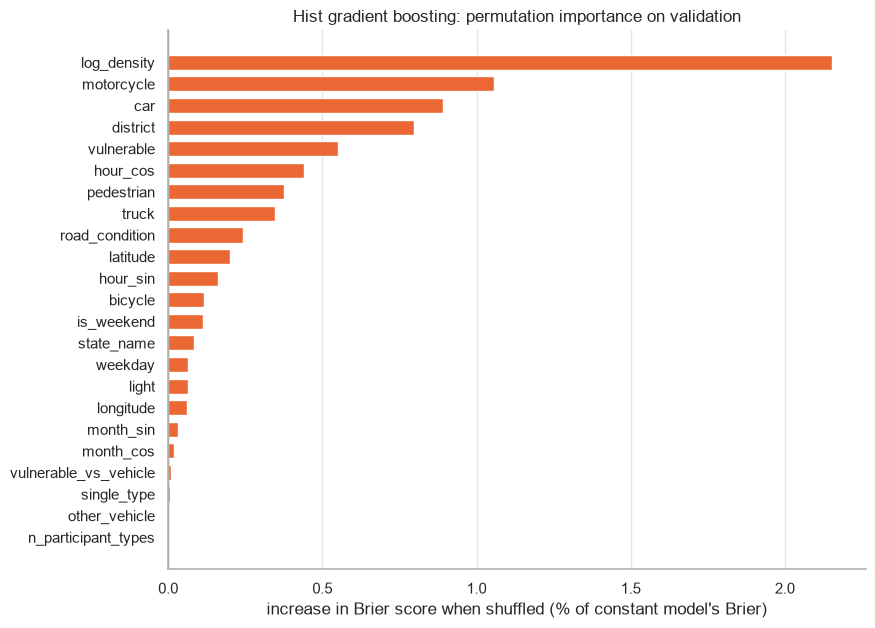

In [21]:
sample = X_val.sample(15_000, random_state=RANDOM_STATE)
importance = permutation_importance(
    hist_gb, sample, y_val.loc[sample.index], scoring="neg_mean_squared_error",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
imp = pd.Series(importance.importances_mean, index=FEATURES).sort_values()
imp = imp / brier_constant * 100  # in % of the constant model's Brier score

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(imp.index, imp.values, color=COLORS["Hist gradient boosting"], height=0.7)
ax.axvline(0, color=REFERENCE, lw=1)
ax.set(xlabel="increase in Brier score when shuffled (% of constant model's Brier)",
       title="Hist gradient boosting: permutation importance on validation")
ax.grid(axis="y", visible=False)
plt.show()

## 10. Save the model

Only the tuned hist gradient boosting is saved (0.4 MB), so the final notebook can score the test set without refitting.
The stack is not saved: with its 400-tree forests it is about 160 MB, which is too large for GitHub (100 MB limit), and it is only marginally better (see the summary).

In [22]:
MODEL_DIR.mkdir(exist_ok=True)
path = MODEL_DIR / "ensemble_hist_gb.joblib"
joblib.dump(hist_gb, path, compress=3)
print(f"saved {path} ({path.stat().st_size / 1e6:.1f} MB)")

saved models/ensemble_hist_gb.joblib (0.4 MB)


## 11. Summary

`accident_kind` and `accident_type` are **not used** (they describe how the accident happened, see section 2), so all
scores are lower than in the earlier run with these two features (linear Brier skill 0.059 → 0.046, best ensemble 0.075 → 0.052).

| | family | Brier skill | ROC-AUC | PR-AUC | F1 (val threshold) |
| --- | --- | --- | --- | --- | --- |
| Linear regression (reference) | – | 0.046 | 0.663 | 0.263 | 0.338 |
| Single tree | – | −0.012 | 0.611 | 0.228 | 0.303 |
| Bagging (trees) | bagging | 0.048 | 0.665 | 0.269 | 0.340 |
| Random forest | bagging | 0.050 | 0.668 | 0.272 | 0.342 |
| Extra trees | bagging | 0.049 | 0.668 | 0.270 | 0.342 |
| AdaBoost | boosting | 0.018 | 0.647 | 0.250 | 0.327 |
| Gradient boosting | boosting | 0.050 | 0.669 | 0.269 | 0.341 |
| **Hist gradient boosting (tuned)** | boosting | **0.051** | **0.670** | **0.272** | **0.344** |
| Voting (average) | stacking | 0.051 | 0.670 | 0.273 | 0.344 |
| **Stacking** | stacking | **0.051** | **0.671** | **0.273** | **0.345** |

* **Without the accident description, ensembles beat the linear reference only slightly.** Brier skill rises from 0.046 to
  0.051 (about +11 %, before it was +25 %), PR-AUC from 0.263 to 0.272, and the top risk decile goes from 32.0 % to 33.2 %
  severe accidents (base rate 15.7 %). Much of the interaction gain the trees found before came from `accident_kind` ×
  road user / location; the remaining features are mostly additive. All good ensembles stay well calibrated.
* **Bagging works because it removes variance.** A single tree is now *worse* than the constant model (Brier skill −0.012);
  100 bagged copies of the same tree reach 0.048. Feature subsampling (random forest) adds a little more. The OOB search now
  prefers larger leaves (`min_samples_leaf=100`): with weaker features, the trees need more smoothing.
* **Boosting:** the tuned hist gradient boosting is again the best single model and trains in seconds. AdaBoost.R2 remains
  a poor fit for a 0/1 target.
* **Stacking gives the best scores, but only by a hair** (+0.0007 Brier skill over hist gradient boosting). The meta-model puts
  0.61 on hist gradient boosting, 0.22 on extra trees, 0.14 on the random forest and 0.08 on linear regression. The gaps
  between the good ensembles are well within the validation noise.
* **What matters now:** population density (`log_density`) is by far the most important feature, followed by the road users
  (motorcycle, car, vulnerable road user, pedestrian, truck), the district target encoding and the hour of day. Severity is
  driven mainly by **where** (urban vs. rural) and **who** is involved.

**Recommendation:** carry **hist gradient boosting** forward as the main model. It is practically as good as the stack,
0.4 MB instead of ~160 MB, fast to retrain and simpler to explain. Keep the stack as a "best possible" reference.
Note that `tiziano_baselines.ipynb` still uses these two features (`UART`, `UTYP1`), so its numbers are not directly comparable.

**Next steps:** error analysis on validation (which kinds of severe accidents get low scores?); try `HistGradientBoostingRegressor`
with native categorical support instead of one-hot; an urban/rural × road-user interaction check; then score the **test set once**
with the saved model and the validation threshold (0.169).
